BIOSENTINEL AI — GENOMIC RISK INTELLIGENCE

[1] DATASET AUDIT
---------------------------------------------
Dataset shape: (2000, 15)
Duplicate rows: 0

Target distribution:
synthetic_amr_label
1    1351
0     649
Name: count, dtype: int64

Missing values:
collection_year        80
gene_marker_2          80
gene_marker_1          80
gene_marker_3          80
gene_marker_4          80
mutation_score         80
gene_marker_5          80
biofilm_score          80
growth_rate            80
efflux_activity        80
porin_loss_score       80
gc_content             80
lineage                 0
isolate_id              0
synthetic_amr_label     0

[2] EXPLORATORY DATA ANALYSIS
---------------------------------------------
                      count unique        top freq         mean       std  \
isolate_id             2000   2000  ISO_01983    1          NaN       NaN   
lineage                2000      6  Lineage_A  360          NaN       NaN   
collection_year      1920.0    NaN        NaN

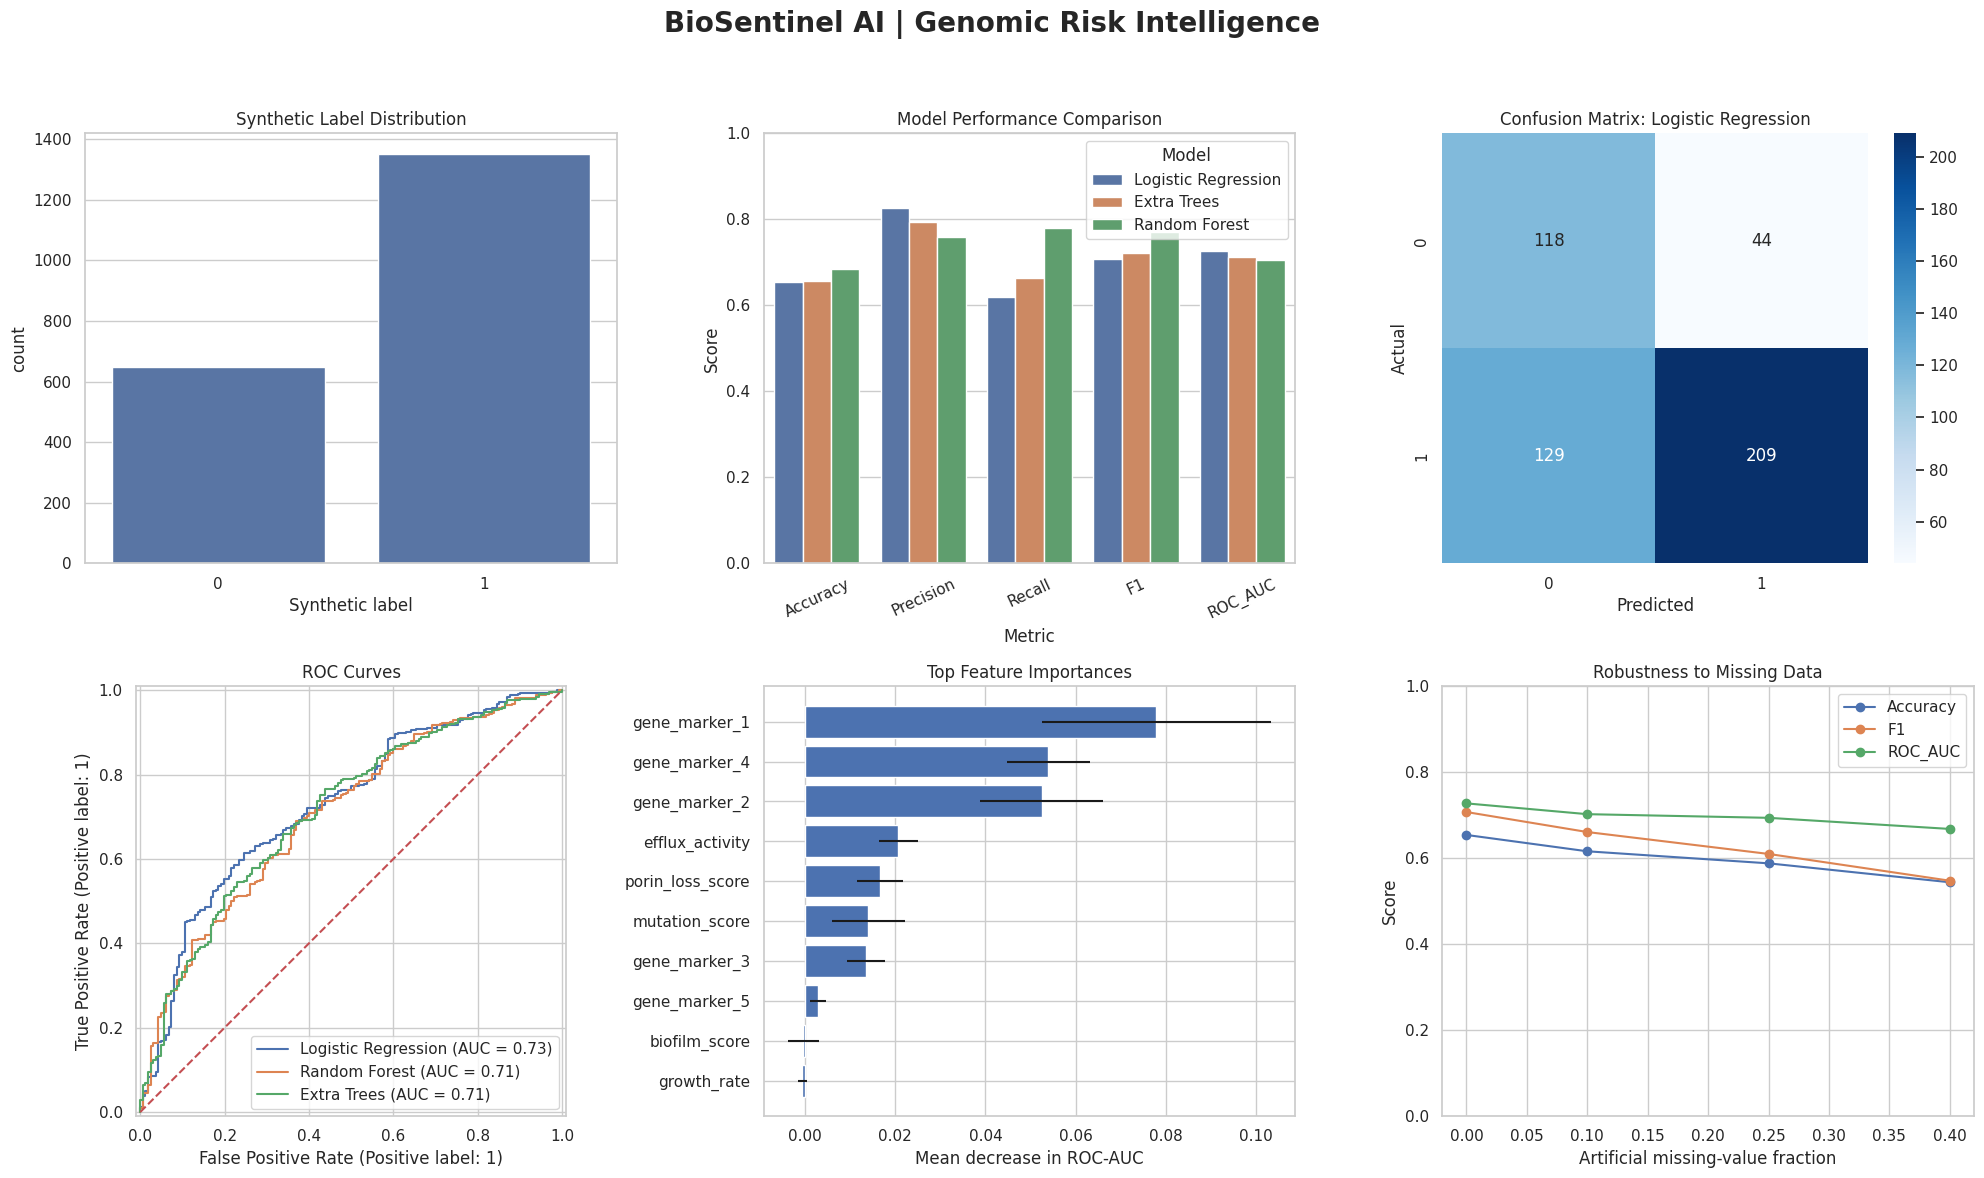


PROJECT COMPLETED SUCCESSFULLY
Output directory: /content/BioSentinel_AI_Results

Generated files:
 • README.md
 • best_demo_model.joblib
 • biosentinel_ai_dashboard.png
 • cross_validation_results.csv
 • holdout_predictions.csv
 • lineage_grouped_validation.csv
 • missingness_robustness.csv
 • model_comparison.csv
 • permutation_feature_importance.csv
 • run_metadata.json
 • synthetic_genomic_dataset.csv

GitHub repository suggestion:
biosentinel-ai-genomic-risk-intelligence

Reminder: all results use synthetic data, not real clinical evidence.


In [1]:

# ================================================================
# BIOSENTINEL AI: GENOMIC RISK INTELLIGENCE
# Complete End-to-End Machine Learning Project in ONE CELL
# Data generation | EDA | ML | Cross-validation | Explainability
# Robustness | Visualizations | Model saving | CSV exports
# ================================================================

import sys
import subprocess
import importlib.util
import warnings
import json
from pathlib import Path

warnings.filterwarnings("ignore")

# 1. INSTALL REQUIRED LIBRARIES
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "joblib": "joblib"
}

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package]
        )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GroupKFold
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

SEED = 42
rng = np.random.default_rng(SEED)
OUTPUT = Path("BioSentinel_AI_Results")
OUTPUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

print("=" * 75)
print("BIOSENTINEL AI — GENOMIC RISK INTELLIGENCE")
print("=" * 75)

# 2. SYNTHETIC DATASET GENERATION
# Simulated genomic markers and phenotypic proxy features.
# These are NOT real biological measurements.

n = 2000

data = pd.DataFrame({
    "isolate_id": [f"ISO_{i:05d}" for i in range(n)],
    "lineage": rng.choice(
        ["Lineage_A", "Lineage_B", "Lineage_C",
         "Lineage_D", "Lineage_E", "Lineage_F"], size=n
    ),
    "collection_year": rng.integers(2018, 2027, size=n),
    "gene_marker_1": rng.binomial(1, 0.32, size=n),
    "gene_marker_2": rng.binomial(1, 0.24, size=n),
    "gene_marker_3": rng.binomial(1, 0.18, size=n),
    "gene_marker_4": rng.binomial(1, 0.40, size=n),
    "gene_marker_5": rng.binomial(1, 0.12, size=n),
    "mutation_score": rng.beta(2, 5, size=n),
    "efflux_activity": rng.beta(3, 3, size=n),
    "porin_loss_score": rng.beta(2, 4, size=n),
    "biofilm_score": rng.beta(2, 3, size=n),
    "growth_rate": rng.normal(0.65, 0.12, size=n),
    "gc_content": rng.normal(0.52, 0.035, size=n)
})

lineage_effect = data["lineage"].map({
    "Lineage_A": 0.45,
    "Lineage_B": 0.20,
    "Lineage_C": -0.25,
    "Lineage_D": 0.35,
    "Lineage_E": -0.10,
    "Lineage_F": 0.05
}).to_numpy()

# Artificial target-generation mechanism for a reproducible demo.
signal = (
    -1.7
    + 1.30 * data["gene_marker_1"]
    + 1.00 * data["gene_marker_2"]
    + 0.75 * data["gene_marker_3"]
    + 0.85 * data["gene_marker_4"]
    + 0.60 * data["gene_marker_5"]
    + 1.40 * data["mutation_score"]
    + 1.15 * data["efflux_activity"]
    + 1.00 * data["porin_loss_score"]
    + 0.35 * data["biofilm_score"]
    + lineage_effect
    + rng.normal(0, 0.65, size=n)
)

prob = 1 / (1 + np.exp(-signal))
data["synthetic_amr_label"] = rng.binomial(1, prob)

# Add missing values to simulate imperfect research data.
feature_cols = [
    c for c in data.columns
    if c not in ["isolate_id", "lineage", "synthetic_amr_label"]
]

for col in feature_cols:
    missing_indices = rng.choice(
        n, size=int(n * 0.04), replace=False
    )
    data.loc[missing_indices, col] = np.nan

data.to_csv(OUTPUT / "synthetic_genomic_dataset.csv", index=False)

print("\n[1] DATASET AUDIT")
print("-" * 45)
print("Dataset shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("\nTarget distribution:")
print(data["synthetic_amr_label"].value_counts())
print("\nMissing values:")
print(data.isna().sum().sort_values(ascending=False).to_string())

# 3. EXPLORATORY DATA ANALYSIS
print("\n[2] EXPLORATORY DATA ANALYSIS")
print("-" * 45)
print(data.describe(include="all").transpose().head(15))

# Exclude identifiers and lineage from model predictors.
# Exclude collection_year in this demo to reduce irrelevant shortcuts.
X = data[feature_cols].drop(
    columns=["collection_year"], errors="ignore"
).copy()

y = data["synthetic_amr_label"].copy()
groups = data["lineage"].copy()

# Holdout evaluation.
X_train, X_test, y_train, y_test, groups_train, groups_test = (
    train_test_split(
        X, y, groups,
        test_size=0.25,
        random_state=SEED,
        stratify=y
    )
)

# 4. DEFINE MACHINE LEARNING PIPELINES
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1500, class_weight="balanced"
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=250,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        ))
    ])
}

# 5. TRAINING AND HOLDOUT EVALUATION
print("\n[3] TRAINING MODELS")
print("-" * 45)

fitted_models = {}
model_predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    fitted_models[name] = model
    model_predictions[name] = (predictions, probabilities)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
)
results_df.to_csv(OUTPUT / "model_comparison.csv", index=False)

print(results_df.round(4).to_string(index=False))

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions, best_probabilities = model_predictions[best_model_name]

print("\nBest baseline by holdout ROC-AUC:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions, zero_division=0
))

# Save holdout predictions.
prediction_df = pd.DataFrame({
    "isolate_id": data.loc[X_test.index, "isolate_id"].values,
    "actual_synthetic_label": y_test.values,
    "predicted_synthetic_label": best_predictions,
    "predicted_probability": best_probabilities
})
prediction_df.to_csv(OUTPUT / "holdout_predictions.csv", index=False)

# 6. STRATIFIED CROSS-VALIDATION
print("\n[4] STRATIFIED CROSS-VALIDATION")
print("-" * 45)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        n_jobs=-1
    )
    cv_results.append({
        "Model": name,
        "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
        "CV_Accuracy_Std": scores["test_accuracy"].std(),
        "CV_F1_Mean": scores["test_f1"].mean(),
        "CV_ROC_AUC_Mean": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)
cv_df.to_csv(OUTPUT / "cross_validation_results.csv", index=False)
print(cv_df.round(4).to_string(index=False))

# 7. LINEAGE-GROUPED VALIDATION
# Keeps all isolates from each lineage together in a fold.
# This is a small synthetic demonstration, not external validation.
print("\n[5] LINEAGE-GROUPED VALIDATION")
print("-" * 45)

grouped_rows = []
n_groups = groups_train.nunique()

if n_groups >= 3:
    group_cv = GroupKFold(n_splits=min(3, n_groups))

    for name, model in models.items():
        fold_aucs = []
        for tr_idx, val_idx in group_cv.split(
            X_train, y_train, groups_train
        ):
            y_fold_train = y_train.iloc[tr_idx]
            y_fold_val = y_train.iloc[val_idx]

            if y_fold_train.nunique() < 2 or y_fold_val.nunique() < 2:
                continue

            fold_model = clone(model)
            fold_model.fit(X_train.iloc[tr_idx], y_fold_train)
            fold_probs = fold_model.predict_proba(
                X_train.iloc[val_idx]
            )[:, 1]

            fold_aucs.append(
                roc_auc_score(y_fold_val, fold_probs)
            )

        grouped_rows.append({
            "Model": name,
            "Mean_Grouped_ROC_AUC": (
                np.mean(fold_aucs) if fold_aucs else np.nan
            ),
            "Valid_Folds": len(fold_aucs)
        })

    grouped_df = pd.DataFrame(grouped_rows)
    grouped_df.to_csv(
        OUTPUT / "lineage_grouped_validation.csv", index=False
    )
    print(grouped_df.round(4).to_string(index=False))

# 8. EXPLAINABILITY WITH PERMUTATION IMPORTANCE
print("\n[6] MODEL EXPLAINABILITY")
print("-" * 45)

permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=8,
    random_state=SEED,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance_Mean": permutation.importances_mean,
    "Importance_Std": permutation.importances_std
}).sort_values("Importance_Mean", ascending=False)

importance_df.to_csv(
    OUTPUT / "permutation_feature_importance.csv", index=False
)
print(importance_df.head(12).round(4).to_string(index=False))

# 9. ROBUSTNESS TO MISSING VALUES
print("\n[7] ROBUSTNESS TESTING")
print("-" * 45)

robustness_results = []

for missing_rate in [0.00, 0.10, 0.25, 0.40]:
    corrupted = X_test.copy()
    local_rng = np.random.default_rng(
        SEED + int(missing_rate * 1000)
    )

    values = corrupted.to_numpy(dtype=float, copy=True)
    mask = local_rng.random(values.shape) < missing_rate
    values[mask] = np.nan

    corrupted = pd.DataFrame(
        values, columns=X_test.columns, index=X_test.index
    )

    pred = best_model.predict(corrupted)
    scores = best_model.predict_proba(corrupted)[:, 1]

    robustness_results.append({
        "Artificial_Missing_Rate": missing_rate,
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, scores)
    })

robustness_df = pd.DataFrame(robustness_results)
robustness_df.to_csv(
    OUTPUT / "missingness_robustness.csv", index=False
)
print(robustness_df.round(4).to_string(index=False))

# 10. GENERATE PROFESSIONAL VISUALIZATIONS
print("\n[8] GENERATING VISUALIZATIONS")
print("-" * 45)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle(
    "BioSentinel AI | Genomic Risk Intelligence",
    fontsize=20, fontweight="bold"
)

# A. Class distribution
sns.countplot(
    data=data, x="synthetic_amr_label", ax=axes[0, 0]
)
axes[0, 0].set_title("Synthetic Label Distribution")
axes[0, 0].set_xlabel("Synthetic label")

# B. Model metric comparison
melted = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(
    data=melted, x="Metric", y="Score",
    hue="Model", ax=axes[0, 1]
)
axes[0, 1].set_title("Model Performance Comparison")
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].set_ylim(0, 1)

# C. Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 2])
axes[0, 2].set_title(f"Confusion Matrix: {best_model_name}")
axes[0, 2].set_xlabel("Predicted")
axes[0, 2].set_ylabel("Actual")

# D. ROC curves
for name, (_, score) in model_predictions.items():
    RocCurveDisplay.from_predictions(
        y_test, score, name=name, ax=axes[1, 0]
    )
axes[1, 0].plot([0, 1], [0, 1], linestyle="--")
axes[1, 0].set_title("ROC Curves")

# E. Feature importance
top_features = importance_df.head(10).sort_values("Importance_Mean")
axes[1, 1].barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)
axes[1, 1].set_title("Top Feature Importances")
axes[1, 1].set_xlabel("Mean decrease in ROC-AUC")

# F. Missingness robustness
for metric in ["Accuracy", "F1", "ROC_AUC"]:
    axes[1, 2].plot(
        robustness_df["Artificial_Missing_Rate"],
        robustness_df[metric],
        marker="o",
        label=metric
    )
axes[1, 2].set_title("Robustness to Missing Data")
axes[1, 2].set_xlabel("Artificial missing-value fraction")
axes[1, 2].set_ylabel("Score")
axes[1, 2].set_ylim(0, 1)
axes[1, 2].legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(
    OUTPUT / "biosentinel_ai_dashboard.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

# 11. SAVE MODEL AND RUN METADATA
joblib.dump(best_model, OUTPUT / "best_demo_model.joblib")

metadata = {
    "project_name": "BioSentinel AI",
    "purpose": "Synthetic genomic AMR ML demonstration",
    "random_seed": SEED,
    "selected_baseline_model": best_model_name,
    "features": list(X.columns),
    "target": "synthetic_amr_label",
    "data_type": "synthetic",
    "clinical_use": False
}

with open(OUTPUT / "run_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

# 12. EXPORT A README STARTER
readme = """# BioSentinel AI — Genomic Risk Intelligence

## Overview
An educational machine-learning prototype exploring genomic-style
features, model evaluation, permutation importance, and robustness.

## Important limitations
- This repository's included dataset is synthetic.
- Its labels are generated by an artificial mathematical rule.
- Metrics do not demonstrate real antimicrobial-resistance performance.
- It is not a diagnostic or treatment recommendation system.

## Features
- Reproducible synthetic data generation
- Missing-value auditing and imputation
- Logistic Regression, Random Forest, and Extra Trees
- Holdout evaluation and stratified cross-validation
- Demonstration lineage-grouped validation
- Permutation feature importance
- Missing-data robustness experiment
- Visual dashboard and saved model artifact

## Run
Install numpy, pandas, matplotlib, seaborn, scikit-learn, and joblib.
Run the notebook cell to regenerate the dataset, metrics, plots, and model.

## Research extension
Replace synthetic data with a documented, appropriately licensed
dataset and validated susceptibility labels. Use appropriate
organism/antibiotic definitions, group-aware evaluation, and
independent external validation before making biological claims.
"""

(OUTPUT / "README.md").write_text(readme, encoding="utf-8")

print("\n" + "=" * 75)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Output directory:", OUTPUT.resolve())
print("\nGenerated files:")
for file in sorted(OUTPUT.iterdir()):
    print(" •", file.name)

print("\nGitHub repository suggestion:")
print("biosentinel-ai-genomic-risk-intelligence")
print("\nReminder: all results use synthetic data, not real clinical evidence.")
